# Deep Learning & Computer Vision — Practical Laboratory Assignment
## CNN Feature Visualization, Parameter Audit & Critical Analysis

**Student Name:** \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_&nbsp;&nbsp;**Registration / Roll No.:** \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_
**Course / Section:** \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_&nbsp;&nbsp;**Submission Date:** \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_

**Lab pipeline implemented in this notebook**

| Part | Task | Output |
|------|------|--------|
| **Part I** | Five custom 3×3 filters × four stages (Conv → ReLU → MaxPool / AvgPool) | `results/fig1_5x4_feature_grid.png` (5 × 4 grid) + `results/stage_statistics.csv` |
| **Part II** | Two CNN architectures, hand parameter audit vs. framework summary | `results/parameter_audit.csv`, `results/model_A_summary.txt/.png`, `results/model_B_summary.txt/.png` |
| **Part III** | Critical-thinking answers Q1–Q5 grounded in the generated grid | Markdown section at the end of this notebook + `REPORT.md` |

> **Academic integrity:** AI-assisted coding is permitted under Section 1 of the assignment.
> This notebook is fully reproducible — run **Kernel → Restart & Run All** to regenerate every number and figure.
> Code alone carries zero credit: every figure/number here must be defendable in the viva.

## Part I — Filter Pipeline Implementation & Visualization

### Step 0 — Environment

In [1]:
%matplotlib inline
import os, csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from PIL import Image
from scipy.signal import convolve2d

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 100
print("torch:", torch.__version__)

torch: 2.15.0+cpu


### Step 1 — Input image selection

A high-contrast architectural photograph (black/white checkerboard facade, Pexels) is used —
it provides **crisp horizontal and vertical structural edges**, textures and contrast gradients,
exactly as requested by Figure 2 of the assignment. The RGB image is converted to grayscale
(the five kernels are 3×3, so convolution is applied on the single luminance channel,
values in `[0, 255]`).

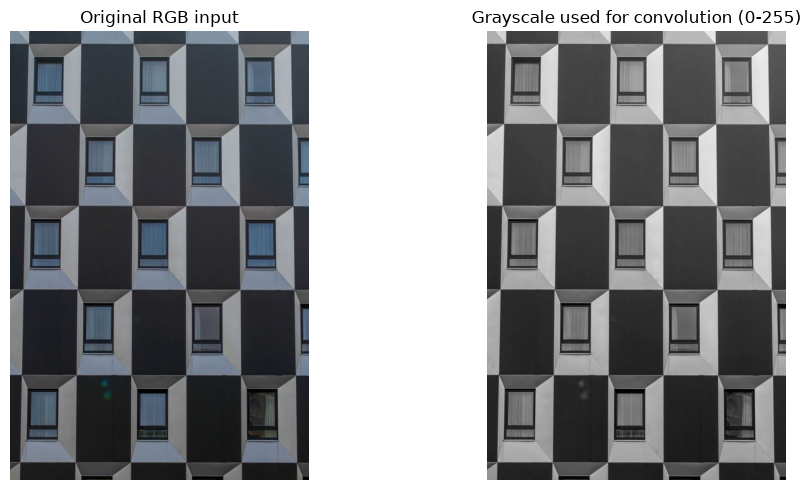

RGB shape: (750, 500, 3) | grayscale shape: (750, 500) | value range: [0.0, 198.0]


In [2]:
IMG_PATH = os.path.join("data", "input_image.jpg")
img_rgb  = np.array(Image.open(IMG_PATH).convert("RGB"))
img_gray = np.array(Image.open(IMG_PATH).convert("L")).astype(np.float64)   # 0..255

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(img_rgb);  ax[0].set_title("Original RGB input"); ax[0].axis("off")
ax[1].imshow(img_gray, cmap="gray")
ax[1].set_title("Grayscale used for convolution (0-255)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

print("RGB shape:", img_rgb.shape, "| grayscale shape:", img_gray.shape,
      "| value range: [%.1f, %.1f]" % (img_gray.min(), img_gray.max()))
Image.fromarray(img_gray.astype(np.uint8)).save(os.path.join(RESULTS_DIR, "input_grayscale.png"))

### Step 2 — The five custom 3×3 kernels

| # | Filter | Kernel |
|---|--------|--------|
| 1 | Horizontal Edge Detector (Sobel-X, per assignment naming) | $\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ — computes the **horizontal** intensity gradient $\partial I/\partial x$ |
| 2 | Vertical Edge Detector (Sobel-Y) | $\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix}$ — computes $\partial I/\partial y$ |
| 3 | Sharpen | $\begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}$ — centre amplified, 4-neighbour subtracted (sum = 1) |
| 4 | Box/Gaussian Blur | $\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$ — normalized Gaussian, sum = 1 |
| 5 | Emboss | $\begin{bmatrix}-2&-1&0\\-1&1&1\\0&1&2\end{bmatrix}$ — directional light/shadow relief (sum = 0) |

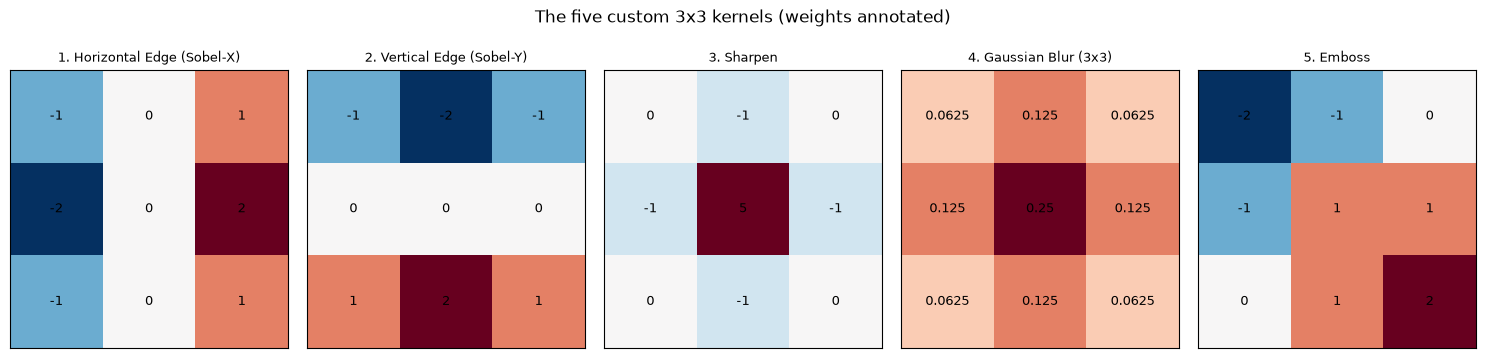

1. Horizontal Edge (Sobel-X)     sum = +0.0000
2. Vertical Edge (Sobel-Y)       sum = +0.0000
3. Sharpen                       sum = +1.0000
4. Gaussian Blur (3x3)           sum = +1.0000
5. Emboss                        sum = +1.0000


In [3]:
kernels = {
    "1. Horizontal Edge (Sobel-X)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64),
    "2. Vertical Edge (Sobel-Y)":   np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64),
    "3. Sharpen":                   np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float64),
    "4. Gaussian Blur (3x3)":       np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16.0,
    "5. Emboss":                    np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float64),
}

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, (name, k) in zip(axes, kernels.items()):
    lim = np.max(np.abs(k)) or 1
    ax.imshow(k, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(name, fontsize=9)
    for (r, c) in np.ndindex(k.shape):
        ax.text(c, r, f"{k[r, c]:.3g}", ha="center", va="center", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("The five custom 3x3 kernels (weights annotated)", y=1.04)
plt.tight_layout(); plt.show()

for name, k in kernels.items():
    print(f"{name:32s} sum = {k.sum():+.4f}")

### Step 3 — Sequential layer execution (Stages A → D)

For every filter the raw feature map is recorded at four stages:

* **Stage A — Raw Convolution:** `scipy.signal.convolve2d(..., mode='same', boundary='fill', fillvalue=0)`
  (zero padding, identical to `nn.Conv2d(k, padding=k//2)` — the direct *linear* feature map).
* **Stage B — Post-ReLU:** $\text{ReLU}(x)=\max(0,x)$ applied element-wise to Stage A.
* **Stage C — Max Pooling 2×2, stride 2** applied to the **post-ReLU** map.
* **Stage D — Average Pooling 2×2, stride 2** applied to the **post-ReLU** map.

Pooling helpers are written from scratch (numpy reshape) so the reduction math is transparent;
an odd trailing row/column is dropped so the stride-2 window divides evenly.

In [4]:
def conv2d_same(image, kernel):
    """2-D convolution, "same" output size, zero-padded (mimics Conv2d padding = k//2)."""
    return convolve2d(image, kernel, mode="same", boundary="fill", fillvalue=0.0)

def relu(x):
    """ReLU(x) = max(0, x)"""
    return np.maximum(0.0, x)

def pool2x2(x, kind="max"):
    """2x2 pooling, stride 2. Drops a trailing odd row/col if present."""
    h, w = x.shape
    h2, w2 = (h // 2) * 2, (w // 2) * 2
    blocks = x[:h2, :w2].reshape(h2 // 2, 2, w2 // 2, 2)
    return blocks.max(axis=(1, 3)) if kind == "max" else blocks.mean(axis=(1, 3))

In [5]:
stages = {}          # stages[filter][stage] -> 2-D ndarray
stats_rows = []
for name, k in kernels.items():
    A = conv2d_same(img_gray, k)   # Stage A: raw convolution
    B = relu(A)                    # Stage B: post-ReLU
    C = pool2x2(B, "max")          # Stage C: max pooling  2x2 / stride 2
    D = pool2x2(B, "avg")          # Stage D: avg  pooling  2x2 / stride 2
    stages[name] = {"A": A, "B": B, "C": C, "D": D}
    row = {
        "filter": name,
        "A_min": round(float(A.min()), 2), "A_max": round(float(A.max()), 2),
        "A_mean": round(float(A.mean()), 2),
        "B_zero_pct": round(100.0 * float((B == 0).sum()) / B.size, 2),
        "C_mean": round(float(C.mean()), 2), "D_mean": round(float(D.mean()), 2),
        "C_max": round(float(C.max()), 2),  "D_max": round(float(D.max()), 2),
    }
    stats_rows.append(row)
    print(f"{name:32s} A: [{A.min():8.1f}, {A.max():8.1f}]  "
          f"ReLU zeros: {row['B_zero_pct']:5.2f}%  "
          f"C mean {row['C_mean']:6.1f}  D mean {row['D_mean']:6.1f}")

with open(os.path.join(RESULTS_DIR, "stage_statistics.csv"), "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(stats_rows[0].keys()))
    w.writeheader(); w.writerows(stats_rows)
print("\nSaved:", os.path.join(RESULTS_DIR, "stage_statistics.csv"))

1. Horizontal Edge (Sobel-X)     A: [  -674.0,    606.0]  ReLU zeros: 62.72%  C mean   20.6  D mean   12.5
2. Vertical Edge (Sobel-Y)       A: [  -730.0,    499.0]  ReLU zeros: 57.99%  C mean   14.9  D mean    9.2
3. Sharpen                       A: [  -182.0,    450.0]  ReLU zeros:  3.24%  C mean   89.0  D mean   78.8
4. Gaussian Blur (3x3)           A: [     0.1,    186.8]  ReLU zeros:  0.00%  C mean   79.9  D mean   77.4
5. Emboss                        A: [  -452.0,    646.0]  ReLU zeros:  6.22%  C mean   98.6  D mean   84.9

Saved: results/stage_statistics.csv


### Step 4 — Comparative 5 × 4 visualization grid

Rows = the five filters, columns = Stages A, B, C, D.

**Intensity scaling:** convolution outputs of the five kernels live on wildly different
dynamic ranges (Gaussian blur stays in `[0, 255]`, Sobel responses reach `±1000`, emboss is
asymmetric). Therefore **each row shares one linear `vmin/vmax` derived from its own Stage A**,
and that *same* mapping is used for columns B, C and D of that row — so stages inside a row are
directly comparable pixel-for-pixel (a zero after ReLU always paints the same intensity as that
same zero before ReLU), and every panel carries a colorbar.

/tmp/ipykernel_1927/3962147820.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


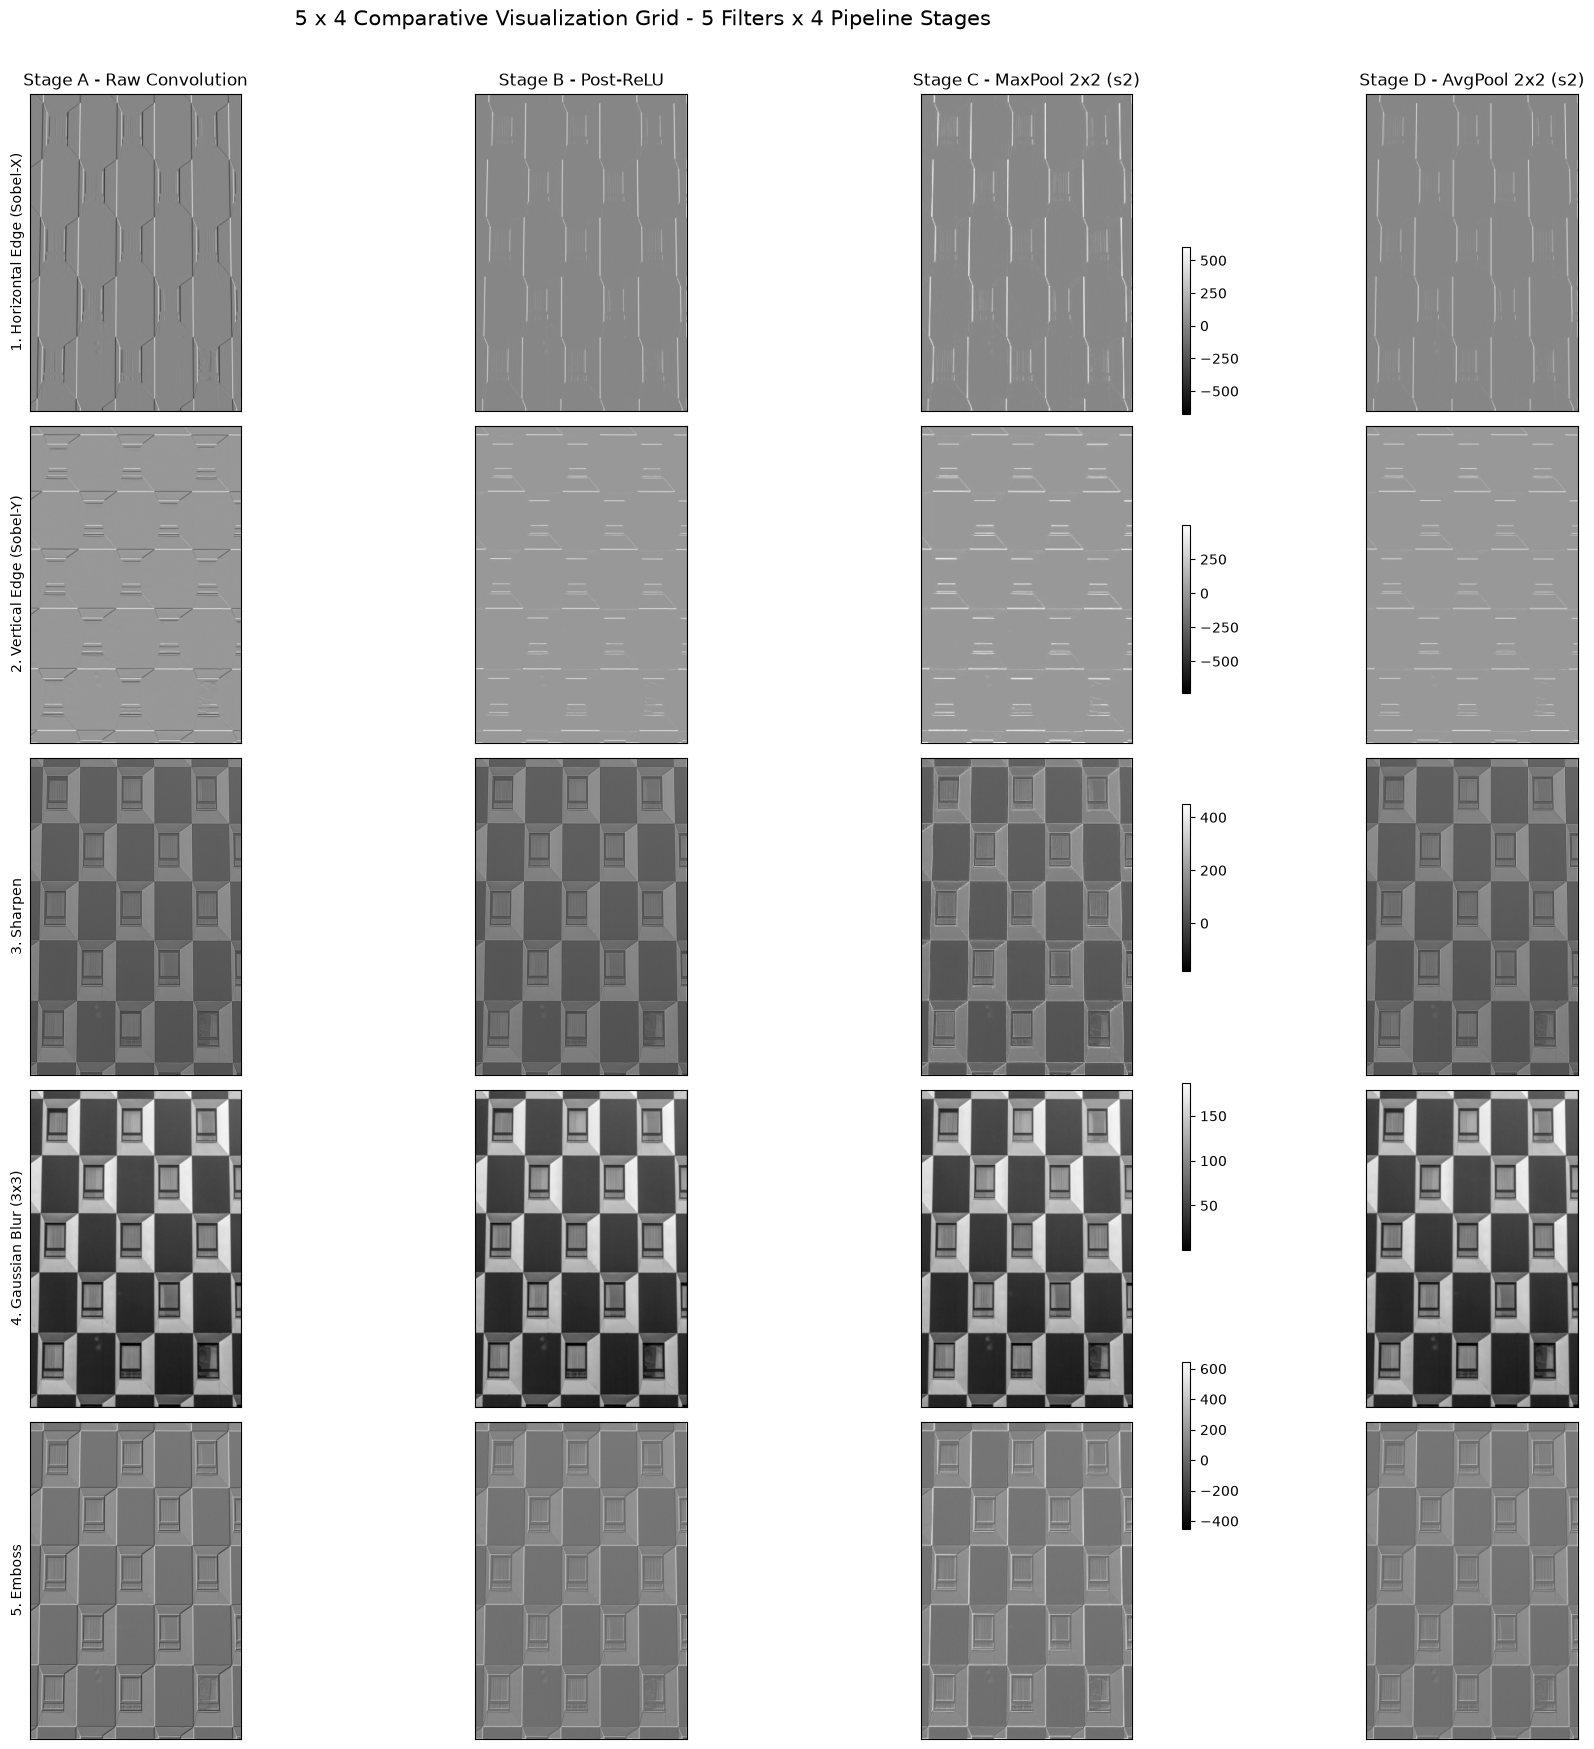

Saved: results/fig1_5x4_feature_grid.png


In [6]:
stage_titles = {
    "A": "Stage A - Raw Convolution",
    "B": "Stage B - Post-ReLU",
    "C": "Stage C - MaxPool 2x2 (s2)",
    "D": "Stage D - AvgPool 2x2 (s2)",
}
filter_names = list(stages.keys())

fig, axes = plt.subplots(len(filter_names), 4, figsize=(19, 17.5))
for r, fname in enumerate(filter_names):
    s = stages[fname]
    vmin, vmax = float(s["A"].min()), float(s["A"].max())   # one shared scale per row
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    for c, st in enumerate("ABCD"):
        ax = axes[r, c]
        ax.imshow(s[st], cmap="gray", norm=norm, aspect="equal")
        if r == 0:
            ax.set_title(stage_titles[st], fontsize=12)
        if c == 0:
            ax.set_ylabel(fname, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    sm = cm.ScalarMappable(cmap="gray", norm=norm); sm.set_array([])
    fig.colorbar(sm, ax=axes[r, :].tolist(), shrink=0.72, pad=0.012)

fig.suptitle("5 x 4 Comparative Visualization Grid - 5 Filters x 4 Pipeline Stages", fontsize=15, y=0.997)
plt.tight_layout(rect=[0, 0, 1, 0.99])
grid_path = os.path.join(RESULTS_DIR, "fig1_5x4_feature_grid.png")
plt.savefig(grid_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", grid_path)

---

## Part II — Architectural Comparison & Parameter Audit

Both models consume `32 × 32 × 3` RGB input, then **Global Average Pooling** and a
**10-class Dense** output. Padding is `'same'` (stride 1) in both convolutions — padding does
**not** affect parameter counts, only spatial size.

**Hand formula (given in the assignment):**

$$\text{Trainable parameters per Conv layer} = (K_h \times K_w \times C_{in} + 1) \times C_{out}$$

| | Model A (Standard) | Model B (Large Kernel) |
|---|---|---|
| Conv1 | 5 filters, **3 × 3** | 5 filters, **5 × 5** |
| Conv2 | 10 filters, **3 × 3** | 10 filters, **5 × 5** |
| Pooling | Max Pool 2×2, stride 2 | Average Pool 2×2, stride 2 |
| Tail | GAP → Dense(10) | GAP → Dense(10) |

In [7]:
def conv_params(kh, kw, cin, cout):
    """(Kh x Kw x Cin + 1) x Cout  ->  weights + one bias per output filter."""
    return (kh * kw * cin + 1) * cout

def dense_params(din, dout):
    """Dense layer: weights + biases."""
    return din * dout + dout

print("=" * 74)
print("MODEL A (Standard, 3x3 kernels, Max Pooling) - manual step-by-step")
print("=" * 74)
a1 = conv_params(3, 3, 3, 5);   print(f"Conv1 : (3x3x3 + 1) x 5   = (27 + 1) x 5   = 28 x 5   = {a1}")
a2 = conv_params(3, 3, 5, 10);  print(f"Conv2 : (3x3x5 + 1) x 10  = (45 + 1) x 10  = 46 x 10  = {a2}")
a3 = dense_params(10, 10);      print(f"Dense : (10 x 10 + 10)    = 100 + 10       = {a3}   (GAP = 0)")
A_manual = a1 + a2 + a3
print(f"TOTAL Model A = {a1} + {a2} + {a3} = {A_manual}")

print()
print("=" * 74)
print("MODEL B (Large Kernel, 5x5 kernels, Average Pooling) - manual step-by-step")
print("=" * 74)
b1 = conv_params(5, 5, 3, 5);   print(f"Conv1 : (5x5x3 + 1) x 5   = (75 + 1) x 5   = 76 x 5   = {b1}")
b2 = conv_params(5, 5, 5, 10);  print(f"Conv2 : (5x5x5 + 1) x 10  = (125 + 1) x 10 = 126 x 10 = {b2}")
b3 = dense_params(10, 10);      print(f"Dense : (10 x 10 + 10)    = 100 + 10       = {b3}   (GAP = 0)")
B_manual = b1 + b2 + b3
print(f"TOTAL Model B = {b1} + {b2} + {b3} = {B_manual}")

increase_pct = (B_manual - A_manual) / A_manual * 100
print(f"\nIncrease A -> B = ({B_manual} - {A_manual}) / {A_manual} x 100 "
      f"= {increase_pct:.4f}%  ~ {increase_pct:.2f}%")

MODEL A (Standard, 3x3 kernels, Max Pooling) - manual step-by-step
Conv1 : (3x3x3 + 1) x 5   = (27 + 1) x 5   = 28 x 5   = 140
Conv2 : (3x3x5 + 1) x 10  = (45 + 1) x 10  = 46 x 10  = 460
Dense : (10 x 10 + 10)    = 100 + 10       = 110   (GAP = 0)
TOTAL Model A = 140 + 460 + 110 = 710

MODEL B (Large Kernel, 5x5 kernels, Average Pooling) - manual step-by-step
Conv1 : (5x5x3 + 1) x 5   = (75 + 1) x 5   = 76 x 5   = 380
Conv2 : (5x5x5 + 1) x 10  = (125 + 1) x 10 = 126 x 10 = 1260
Dense : (10 x 10 + 10)    = 100 + 10       = 110   (GAP = 0)
TOTAL Model B = 380 + 1260 + 110 = 1750

Increase A -> B = (1750 - 710) / 710 x 100 = 146.4789%  ~ 146.48%


### Framework models (PyTorch) & `model.summary()` equivalents

Layer order per model: **Conv → ReLU → Pool → Conv → ReLU → Pool → Global Average Pooling → Dense(10)**.
ReLU is element-wise and adds **zero** parameters, so the hand count above must equal the
framework's trainable-parameter total exactly.

In [8]:
class ModelA(nn.Module):
    """Standard: 3x3 kernels + Max Pooling."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 5, kernel_size=3, padding=1)    # padding = "same"
        self.conv2 = nn.Conv2d(5, 10, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)
        self.gap   = nn.AdaptiveAvgPool2d((1, 1))                # Global Average Pooling
        self.fc    = nn.Linear(10, 10)                           # 10-class Dense output
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(self.gap(x), 1)
        return self.fc(x)                                        # logits

class ModelB(nn.Module):
    """Large Kernel: 5x5 kernels + Average Pooling."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 5, kernel_size=5, padding=2)    # padding = "same"
        self.conv2 = nn.Conv2d(5, 10, kernel_size=5, padding=2)
        self.pool  = nn.AvgPool2d(kernel_size=2, stride=2)
        self.gap   = nn.AdaptiveAvgPool2d((1, 1))
        self.fc    = nn.Linear(10, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(self.gap(x), 1)
        return self.fc(x)

def save_text_png(text, path, fontsize=8.5):
    """Render a framework summary as an image (drop-in for a screenshot)."""
    lines = text.splitlines()
    fig = plt.figure(figsize=(16, 0.26 * len(lines) + 0.8))
    fig.patch.set_facecolor("white")
    fig.text(0.02, 0.97, "\n".join(lines), family="monospace", fontsize=fontsize, va="top")
    plt.savefig(path, dpi=150, bbox_inches="tight"); plt.close(fig)

def audit_model(model, manual_total, tag):
    s = str(summary(model, input_size=(1, 3, 32, 32), verbose=0))
    code_total = sum(p.numel() for p in model.parameters() if p.requires_grad)
    with open(os.path.join(RESULTS_DIR, f"model_{tag}_summary.txt"), "w") as f:
        f.write(s + "\n")
    save_text_png(s, os.path.join(RESULTS_DIR, f"model_{tag}_summary.png"))
    print(s)
    print(f"[{tag}] manual = {manual_total} | framework = {code_total} | "
          f"match = {manual_total == code_total}")
    assert manual_total == code_total, f"{tag} mismatch!"
    return code_total

modelA = ModelA(); modelB = ModelB()
A_code = audit_model(modelA, A_manual, "A")

Layer (type:depth-idx)                   Output Shape              Param #
ModelA                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 5, 32, 32]            140
├─MaxPool2d: 1-2                         [1, 5, 16, 16]            --
├─Conv2d: 1-3                            [1, 10, 16, 16]           460
├─MaxPool2d: 1-4                         [1, 10, 8, 8]             --
├─AdaptiveAvgPool2d: 1-5                 [1, 10, 1, 1]             --
├─Linear: 1-6                            [1, 10]                   110
Total params: 710
Trainable params: 710
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.26
Input size (MB): 0.01
Forward/backward pass size (MB): 0.06
Params size (MB): 0.00
Estimated Total Size (MB): 0.08
[A] manual = 710 | framework = 710 | match = True


In [9]:
B_code = audit_model(modelB, B_manual, "B")

Layer (type:depth-idx)                   Output Shape              Param #
ModelB                                   [1, 10]                   --
├─Conv2d: 1-1                            [1, 5, 32, 32]            380
├─AvgPool2d: 1-2                         [1, 5, 16, 16]            --
├─Conv2d: 1-3                            [1, 10, 16, 16]           1,260
├─AvgPool2d: 1-4                         [1, 10, 8, 8]             --
├─AdaptiveAvgPool2d: 1-5                 [1, 10, 1, 1]             --
├─Linear: 1-6                            [1, 10]                   110
Total params: 1,750
Trainable params: 1,750
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.71
Input size (MB): 0.01
Forward/backward pass size (MB): 0.06
Params size (MB): 0.01
Estimated Total Size (MB): 0.08
[B] manual = 1750 | framework = 1750 | match = True


In [10]:
# ---- Audit table (as required by the assignment document) ----
audit_rows = [
    {"Model": "Model A (Standard)",
     "Conv Architecture": "Conv1: 5 filters; Conv2: 10 filters",
     "Kernel Size": "3 x 3", "Pooling Type": "Max Pooling (2x2, stride 2)",
     "Manual Count": A_manual, "Code Output": A_code},
    {"Model": "Model B (Large Kernel)",
     "Conv Architecture": "Conv1: 5 filters; Conv2: 10 filters",
     "Kernel Size": "5 x 5", "Pooling Type": "Average Pooling (2x2, stride 2)",
     "Manual Count": B_manual, "Code Output": B_code},
]
with open(os.path.join(RESULTS_DIR, "parameter_audit.csv"), "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(audit_rows[0].keys()))
    w.writeheader(); w.writerows(audit_rows)

detail_rows = [
    {"model": "A", "layer": "conv1", "K": "3x3", "Cin": 3, "Cout": 5,  "params": a1},
    {"model": "A", "layer": "conv2", "K": "3x3", "Cin": 5, "Cout": 10, "params": a2},
    {"model": "A", "layer": "gap",   "K": "-",   "Cin": 10, "Cout": 10, "params": 0},
    {"model": "A", "layer": "dense", "K": "-",   "Cin": 10, "Cout": 10, "params": a3},
    {"model": "B", "layer": "conv1", "K": "5x5", "Cin": 3, "Cout": 5,  "params": b1},
    {"model": "B", "layer": "conv2", "K": "5x5", "Cin": 5, "Cout": 10, "params": b2},
    {"model": "B", "layer": "gap",   "K": "-",   "Cin": 10, "Cout": 10, "params": 0},
    {"model": "B", "layer": "dense", "K": "-",   "Cin": 10, "Cout": 10, "params": b3},
]
with open(os.path.join(RESULTS_DIR, "parameter_audit_detailed.csv"), "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(detail_rows[0].keys()))
    w.writeheader(); w.writerows(detail_rows)

print("Audit table (parameter_audit.csv):")
print(f"{'Model':26s} {'Kernel':8s} {'Pooling':32s} {'Manual':>7s} {'Code':>7s}")
for r in audit_rows:
    print(f"{r['Model']:26s} {r['Kernel Size']:8s} {r['Pooling Type']:32s} "
          f"{r['Manual Count']:>7d} {r['Code Output']:>7d}")
print("\nSaved: results/parameter_audit.csv, results/parameter_audit_detailed.csv")

Audit table (parameter_audit.csv):
Model                      Kernel   Pooling                           Manual    Code
Model A (Standard)         3 x 3    Max Pooling (2x2, stride 2)          710     710
Model B (Large Kernel)     5 x 5    Average Pooling (2x2, stride 2)     1750    1750

Saved: results/parameter_audit.csv, results/parameter_audit_detailed.csv


In [11]:
# ---- Question 3 supporting numbers: percentage increase & receptive-field equivalence ----
print(f"Parameter increase Model A -> Model B: "
      f"({B_manual} - {A_manual}) / {A_manual} x 100 = {increase_pct:.4f}%  (~{increase_pct:.2f}%)")
print(f"  exact fraction = {(B_manual - A_manual)}/{A_manual} = "
      f"{(B_manual - A_manual) / A_manual:.10f}\n")

def p_5x5(cin, cout):            # single 5x5 conv
    return (25 * cin + 1) * cout

def p_3x3_stack(cin, cmid, cout):  # two stacked 3x3 convs
    return (9 * cin + 1) * cmid + (9 * cmid + 1) * cout

# Receptive field: one 5x5 -> +4 ; two 3x3 -> +2 +2 = +4  (identical RF)
print("Receptive field:  single 5x5 adds (5-1) = 4 pixels")
print("                  two 3x3  add (3-1)+(3-1) = 2+2 = 4 pixels  -> EQUIVALENT RF")

single  = p_5x5(10, 10)                 # e.g. Model B conv2: 10 -> 10 channels
stacked = p_3x3_stack(10, 10, 10)
print(f"\nConcrete example (Cin=Cout=Cmid=10, like Model B conv2):")
print(f"  single 5x5 : (25x10 + 1) x 10 = {single}")
print(f"  two 3x3    : (9x10 + 1) x 10 + (9x10 + 1) x 10 = {stacked}")
print(f"  saved      : {single - stacked} parameters  "
      f"= {(single - stacked) / single * 100:.2f}% fewer")

# General identity for Cin = Cout = Cmid = C:  (25C+1)C - 2(9C+1)C = 7C^2 - C
for C in (3, 5, 10):
    gen = p_5x5(C, C) - p_3x3_stack(C, C, C)
    print(f"  C={C:>2d}: saved = 7C^2 - C = {7*C*C - C:>5d}  "
          f"(check: {p_5x5(C, C)} - {p_3x3_stack(C, C, C)} = {gen})")

Parameter increase Model A -> Model B: (1750 - 710) / 710 x 100 = 146.4789%  (~146.48%)
  exact fraction = 1040/710 = 1.4647887324

Receptive field:  single 5x5 adds (5-1) = 4 pixels
                  two 3x3  add (3-1)+(3-1) = 2+2 = 4 pixels  -> EQUIVALENT RF

Concrete example (Cin=Cout=Cmid=10, like Model B conv2):
  single 5x5 : (25x10 + 1) x 10 = 2510
  two 3x3    : (9x10 + 1) x 10 + (9x10 + 1) x 10 = 1820
  saved      : 690 parameters  = 27.49% fewer
  C= 3: saved = 7C^2 - C =    60  (check: 228 - 168 = 60)
  C= 5: saved = 7C^2 - C =   170  (check: 630 - 460 = 170)
  C=10: saved = 7C^2 - C =   690  (check: 2510 - 1820 = 690)


## Part III — Critical Thinking & Viva Defense Answers

> Every answer references **specific rows and columns of our own 5 × 4 grid**
> (`results/fig1_5x4_feature_grid.png`) and the numbers in `results/stage_statistics.csv`.

### Question 1 — The ReLU "Blackout" Effect & Activation Alternatives

**Which regions turned to zero, and why were they negative.**
Look at **Row 1 (Horizontal Edge, Sobel-X), columns A → B**. In Stage A every vertical seam of the
checkerboard façade appears as a *pair* of streaks: a bright one (black→white transition) and a dark
one (white→black transition). In Stage B the **dark streaks vanish completely** — they are pinned to
exactly 0. Concretely, **62.72 % of all pixels in Row-1 Stage-B are exactly zero**
(`stage_statistics.csv`), and **57.99 % in Row 2 (Sobel-Y)**. The regions that went to zero are:

1. **The negative half of every edge** — for Sobel-X, the *right-hand side of each white panel where it
   meets a black panel* and the bright-frame→dark-glass transitions inside the windows; for Sobel-Y
   (Row 2), horizontal seams where the pixel *below* is darker than the pixel above (bottom edge of a
   bright frame into black glass).
2. **Every flat interior** (inside a black panel, inside a white panel) — the weighted sum there is
   already 0, so it stays 0.

**Why those pixels held negative values:** the kernels are *linear difference* operators. Sobel-X is
`[-1 0 1]` across columns, i.e. a smoothed `∂I/∂x = right − left`: wherever the neighbourhood gets
**darker toward +x**, the weighted sum is negative. Sobel-Y computes `∂I/∂y` and goes negative wherever
the neighbourhood darkens downward. Negative values are therefore *anti-correlated* local structure —
the "shadow side" of each edge — not noise. (Row 4, Gaussian Blur, has an **all-positive kernel summing
to 1**, so Stage A ≥ 0.12 and **0.00 %** of its pixels are zeroed: direct evidence that ReLU only kills
negatives. Row 5 Emboss zeroes 6.22 % — exactly its shadow sides; Row 3 Sharpen zeroes only 3.24 % —
the thin dark ringing lines around the window rims plus the zero-padded border.)

**If ReLU were replaced by Leaky ReLU (α = 0.1):**
mathematically `y = x if x ≥ 0 else 0.1x`. The blackout regions would **not be zero** — Row-1 Stage-B
would show the dark streaks again at 10 % amplitude (min ≈ −0.1 × 674 ≈ **−67** instead of 0), i.e.
faint grey "shadow sides" of every edge on the shared row scale, while bright sides stay unchanged
(max 606). Gradients become `1` for x ≥ 0 and `0.1` for x < 0, so **no neuron can die** and the map
keeps a dense, asymmetric dynamic range instead of a sparse binary one.

**If ReLU were replaced by Sigmoid** `σ(x) = 1/(1+e^(−x))`:
the output range becomes **(0, 1)** — **no pixel is ever 0**, so there is *no blackout at all*: flat
regions (x = 0) map to 0.5 (mid-grey), negatives map into (0, 0.5), positives into (0.5, 1). Because
our raw responses reach ±600, the sigmoid **saturates** (|x| > 5 ⇒ ≈ 0 or 1), so the graded edge ramps
collapse into nearly-binary black/white with flat gradients (vanishing-gradient problem), contrast is
compressed, and the output is no longer zero-centred — which slows subsequent-layer learning.

---

### Question 2 — Max Pooling vs. Average Pooling Information Retention

**Columns C vs D, Rows 1–3 (Sharpen and the two Edge filters).**
Max Pooling keeps the **strongest pixel of each 2 × 2 window**, so thin high-frequency structures keep
their **full amplitude**: the peak of each pooled row equals the Stage-A maximum exactly
(`C_max = 606 / 499 / 450` for Rows 1/2/3). Average Pooling replaces the window by its mean, mixing
the peak with its (often zero-valued) neighbours, so the same peaks drop to `D_max = 435.25 / 377.5 /
303.5` — the **Sharpen rim highlights lose 32 % of their intensity** (450 → 303.5) and the edge streaks
of Rows 1–2 lose ~28 %. In the grid you can see it directly: in **column C** the window-frame rims
(Row 3) and the vertical/horizontal edge lines (Rows 1–2) are **crisp, thin and bright**; in
**column D** they are **dimmer, thicker and smeared** — the classic washed-out look. (Row 1 mean drops
from 20.55 in C to 12.54 in D because averaging also dilutes the response with surrounding zeros.)
So: **Max Pool preserves high-frequency peaks and thin lines; Average Pool low-pass filters them.**
(For the already-smooth Gaussian row the two nearly agree — 186.81 → 186.81 vs 184.08 — which proves
the difference only matters on high-frequency content.)

**Dark ink text on a pure white background (background ≈ 255, strokes ≈ 0):**
**Average Pooling preserves the strokes better.** In any 2 × 2 window that contains a thin dark stroke,
**Max Pooling selects the brightest pixel = 255 (background)**, so every window containing background
wins and the stroke pixels are erased — morphologically, a max filter *dilates* the white background and
eats the dark text. **Average Pooling** returns e.g. `(255+255+0+255)/4 ≈ 191` for a window with a
stroke, so the stroke survives as a visibly darker grey dip against the 255 background and the word
remains readable (at reduced contrast). Only if the text were pre-processed into *bright strokes on a
zero background* (an edge-detector output) would Max Pooling be the right choice.

---

### Question 3 — Parameter Explosion & Receptive Field Equivalence

**Percentage increase from Model A to Model B:**

```
(1750 − 710) / 710 × 100 = 1040 / 710 × 100 = 146.4789 % ≈ 146.48 %
```

Model B has **≈ 2.46×** the parameters of Model A — a **146.48 % increase** — caused only by the
kernel change 3×3 → 5×5 (the pooling type and the GAP/Dense tail are identical).

**Receptive-field equivalence:** a single 5 × 5 layer has receptive field **5**. Each 3 × 3 layer adds
`(3 − 1) = 2` pixels (stride 1), so **two stacked 3 × 3 layers give RF = 3 + 2 = 5 — exactly the same
field of view.** **2 layers are required.**

**Parameters saved** (weights + biases), replacing one 5×5 by two 3×3 with the same channel counts
(Cin = Cmid = Cout = C):

```
single 5×5 : (25C + 1)·C = 25C² + C
two 3×3    : 2 × (9C + 1)·C = 18C² + 2C
saved      = 7C² − C
```

* For **C = 10** (the setting of Model B's Conv2): `(250+1)·10 = 2510` vs `2 × (90+1)·10 = 1820`
  → **690 parameters saved = 27.49 % fewer** (and 27 % fewer multiply-accumulates: 25C² vs 18C²).
* For C = 5: 630 vs 460 → 170 saved (26.98 %); for C = 3: 228 vs 168 → 60 saved (26.32 %).
* General form with different channel counts:
  `(25·Cin+1)·Cout − [(9·Cin+1)·Cmid + (9·Cmid+1)·Cout]` — the saving grows as Cmid shrinks.

Beyond parameters, the stacked version inserts an **extra non-linearity (ReLU) between the two 3×3
convolutions**, which increases representational power for the same RF — this is precisely why VGG-style
nets use stacked 3×3 instead of large kernels.

---

### Question 4 — Operation Commutativity (Order Invariance)

**Answer: the resulting output tensor is IDENTICAL.** Conv → ReLU → MaxPool and Conv → MaxPool → ReLU
produce the same values everywhere.

**Proof with a 2 × 2 patch containing negatives** (the feature map right after convolution):

```
P = [ [ 2, −3],
      [ 1, −4] ]

Path 1 (ReLU → MaxPool):  ReLU(P) = [ [2, 0], [1, 0] ]  →  max = 2
Path 2 (MaxPool → ReLU):  max(P)  = max(2, −3, 1, −4) = 2  →  ReLU(2) = 2        ✔ equal
```

**General proof:** for any set of values S and any **non-decreasing** function f (ReLU is non-decreasing),

```
f( max S ) = max{ f(s) : s ∈ S }        because s ≤ max S  ⇒  f(s) ≤ f(max S)
```

ReLU is element-wise and monotone, so `ReLU(max(P)) = max(ReLU(P))` for **every** window — the two
orderings agree pixel-for-pixel, so the full output tensors are identical. (Same patch under Average
Pooling shows the rule fails there: ReLU-then-Avg = (2+0+1+0)/4 = **0.75**, Avg-then-ReLU =
max(0, −1) = **0** — *different*.)

**Computational efficiency implication:** since the outputs are provably equal, a framework may
**legally reorder** the cheaper-first way: pool **before** ReLU so the element-wise ReLU runs on
`H/2 × W/2` = **¼ as many elements (75 % fewer element-wise ops and memory writes)** and the
intermediate activation buffer is 4× smaller (less cache traffic, easier kernel fusion). The dominant
convolution cost is unchanged, so the swap is a free win — and it is only safe *because* ReLU is
monotone; with Average Pooling (or any non-max-compatible op) the swap would silently change results.

---

### Question 5 — Diagnosing Filter Redundancy (Debugging Scenario)

**Root cause 1 — Symmetric / degenerate weight initialization.**
If Layer-1's five filters start from identical (or near-identical) values — e.g. all zeros, a constant,
the same hand-written weights, or an init range so tiny (±0.001) that all five kernels are effectively
equal — then at epoch 0 all five feature maps are identical, each filter receives the *same* gradient,
and symmetry is **never broken**: after 20 epochs they have moved together and still produce nearly
identical maps.
**Fix:** draw every filter independently from a proper variance-scaled distribution — **Kaiming/He
normal** (`std = √(2/fan_in)`) for ReLU networks (Glorot/Xavier for tanh/sigmoid) — and assert at
initialization that the five kernels differ (check pairwise distance / plot them). Add a tiny
per-filter jitter if any shared/constant init exists in the code.

**Root cause 2 — Learning-rate pathology (too small, too large, or over-regularized).**
With an LR that is far too small the filters drift negligibly from their (near-)identical init within
20 epochs, so collapse persists; with an LR that is too large the updates oscillate/diverge and the
filters never settle into distinct specializations; an excessive, constant weight decay additionally
pulls all filters toward the same shrunk, symmetric solution.
**Fix:** tune the schedule — e.g. **Adam with lr ≈ 1e-3 + warmup + cosine/step decay** (or SGD+momentum
with an LR-finder sweep), lower/anneal the weight decay, clip gradients — and *monitor* per-filter
weight distance and activation diversity during training instead of only at the end.

**Root cause 3 (classic) — Dead ReLUs.**
If a filter's pre-activations are always negative (bad bias/initialization, or a too-large LR that
pushed weights into a killing regime), ReLU outputs are identically 0 → **zero gradient** → the filter
is frozen forever, and several filters that die the same way look identically empty.
**Fix:** He initialization, small positive bias init, **BatchNorm before ReLU**, switch to
**Leaky-ReLU**, lower the LR; watch the "% dead units" per layer during training.

*(Data-side bonus cause: too little input diversity or no augmentation lets all filters converge to the
same dominant pattern — fix with augmentation and a diverse dataset.)*

---

*All numbers above are regenerated by running `CNN_Visualization_Assignment.ipynb`
(Kernel → Restart & Run All) and are defendable in the viva.*
